In [1]:
!pip install -q einops

In [2]:
import os
import math
import time
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import ReduceLROnPlateau

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Libraries imported.")

Libraries imported.


In [3]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
print(f"Seed set to {SEED}")

Seed set to 42


In [4]:
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

CUDA available: True
GPU Name: Tesla T4
Using device: cuda


In [5]:
from google.colab import files
uploaded = files.upload()
CSV_PATH = list(uploaded.keys())[0]


Saving Xiatang.csv to Xiatang.csv


In [6]:
# --- Load Xiatang.csv ---
# If the file is not already present in this Colab session, upload it now.
import os

CSV_PATH = "Xiatang.csv"  # change this if using Google Drive, e.g. "/content/drive/MyDrive/.../Xiatang.csv"

if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files
        print(f"'{CSV_PATH}' not found in the working directory — please select it in the upload dialog.")
        uploaded = files.upload()
        CSV_PATH = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError(
            f"'{CSV_PATH}' not found and not running in Colab (no upload widget available). "
            "Set CSV_PATH to the correct path manually."
        )

assert os.path.exists(CSV_PATH), f"Still cannot find {CSV_PATH} — check the path/upload."

raw_df = pd.read_csv(CSV_PATH, encoding="utf-8-sig")
raw_df["time"] = pd.to_datetime(raw_df["time"])
raw_df = raw_df.sort_values("time")
raw_df = raw_df.drop_duplicates(subset="time")
raw_df = raw_df.reset_index(drop=True)

print(f"Loaded '{CSV_PATH}' successfully -> raw_df shape: {raw_df.shape}")
print("Station(s):", raw_df["name"].unique())
raw_df.head()


Loaded 'Xiatang.csv' successfully -> raw_df shape: (6946, 11)
Station(s): ['峡塘']


,name,time,TEMP,pH,DO,EC,EUR,COMMn,NH3-N,TP,TN
0,峡塘,2020-12-17 20:00:00,1.60,7.89,13.00,385.25,23.25,1.95,0.03,0.00,1.28
1,峡塘,2020-12-18 20:00:00,1.70,7.88,13.01,383.33,43.00,2.26,0.03,0.00,1.30
2,峡塘,2020-12-19 20:00:00,1.76,7.88,13.03,380.50,44.00,2.24,0.04,0.00,1.27
3,峡塘,2020-12-20 20:00:00,1.83,7.87,13.02,384.16,40.16,3.36,0.04,0.00,1.21
4,峡塘,2020-12-21 20:00:00,1.83,7.87,13.07,390.16,51.16,2.23,0.04,0.04,1.24


In [7]:
FEATURE_COLS = ["TEMP", "pH", "DO", "EC", "EUR", "COMMn", "NH3-N", "TP", "TN"]
TARGET_COL = "DO"
TARGET_IDX = FEATURE_COLS.index(TARGET_COL)  # index of DO within FEATURE_COLS

print("Dataset shape:", raw_df.shape)
print("\nSummary statistics:")
display(raw_df[FEATURE_COLS].describe())

print("\nMissing values:")
print(raw_df[FEATURE_COLS].isna().sum())

Dataset shape: (6946, 11)

Summary statistics:


,TEMP,pH,DO,EC,EUR,COMMn,NH3-N,TP,TN
count,6896.000000,6905.000000,6904.000000,6877.000000,6876.000000,6767.000000,6892.000000,6900.000000,6861.000000
mean,8.115222,8.496987,10.378211,464.561032,97.869520,1.484044,0.059486,0.009472,1.336473
std,5.799623,0.196361,1.832092,43.124351,259.554776,1.787360,0.134242,0.019197,0.333450
min,0.030000,7.850000,3.620000,1.000000,0.605590,0.250000,0.020000,0.000000,0.050000
25%,1.700000,8.370000,9.116722,435.000000,15.686203,0.746780,0.025000,0.005000,1.181810
50%,8.400000,8.488660,10.502375,466.606800,40.000000,1.167110,0.025000,0.005000,1.291880
75%,13.515625,8.689670,11.748530,498.698200,96.000000,1.604510,0.047573,0.008920,1.432300
max,23.034400,8.940000,14.170000,535.160000,9999.000000,26.166470,2.082660,0.457700,9.334750



Missing values:
TEMP      50
pH        41
DO        42
EC        69
EUR       70
COMMn    179
NH3-N     54
TP        46
TN        85
dtype: int64


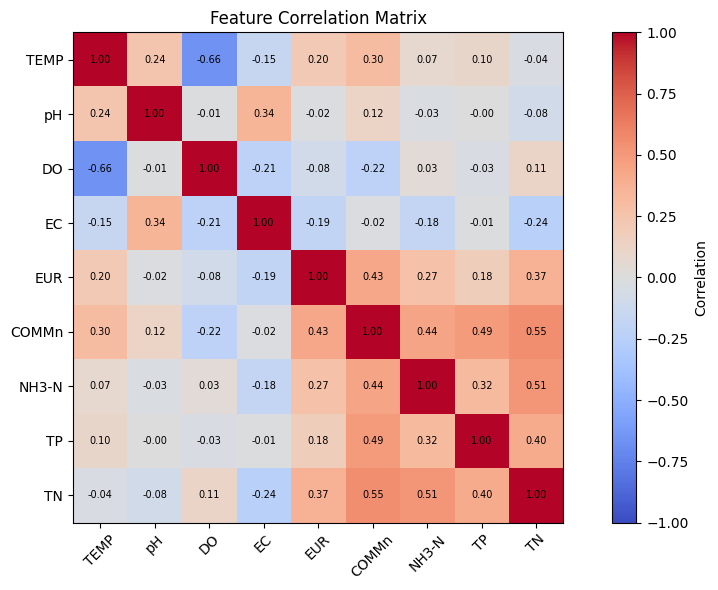

In [8]:
plt.figure(figsize=(10, 6))
corr = raw_df[FEATURE_COLS].corr()
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(FEATURE_COLS)), FEATURE_COLS, rotation=45)
plt.yticks(range(len(FEATURE_COLS)), FEATURE_COLS)
plt.colorbar(label="Correlation")
plt.title("Feature Correlation Matrix")
for i in range(len(FEATURE_COLS)):
    for j in range(len(FEATURE_COLS)):
        plt.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=7)
plt.tight_layout()
plt.show()

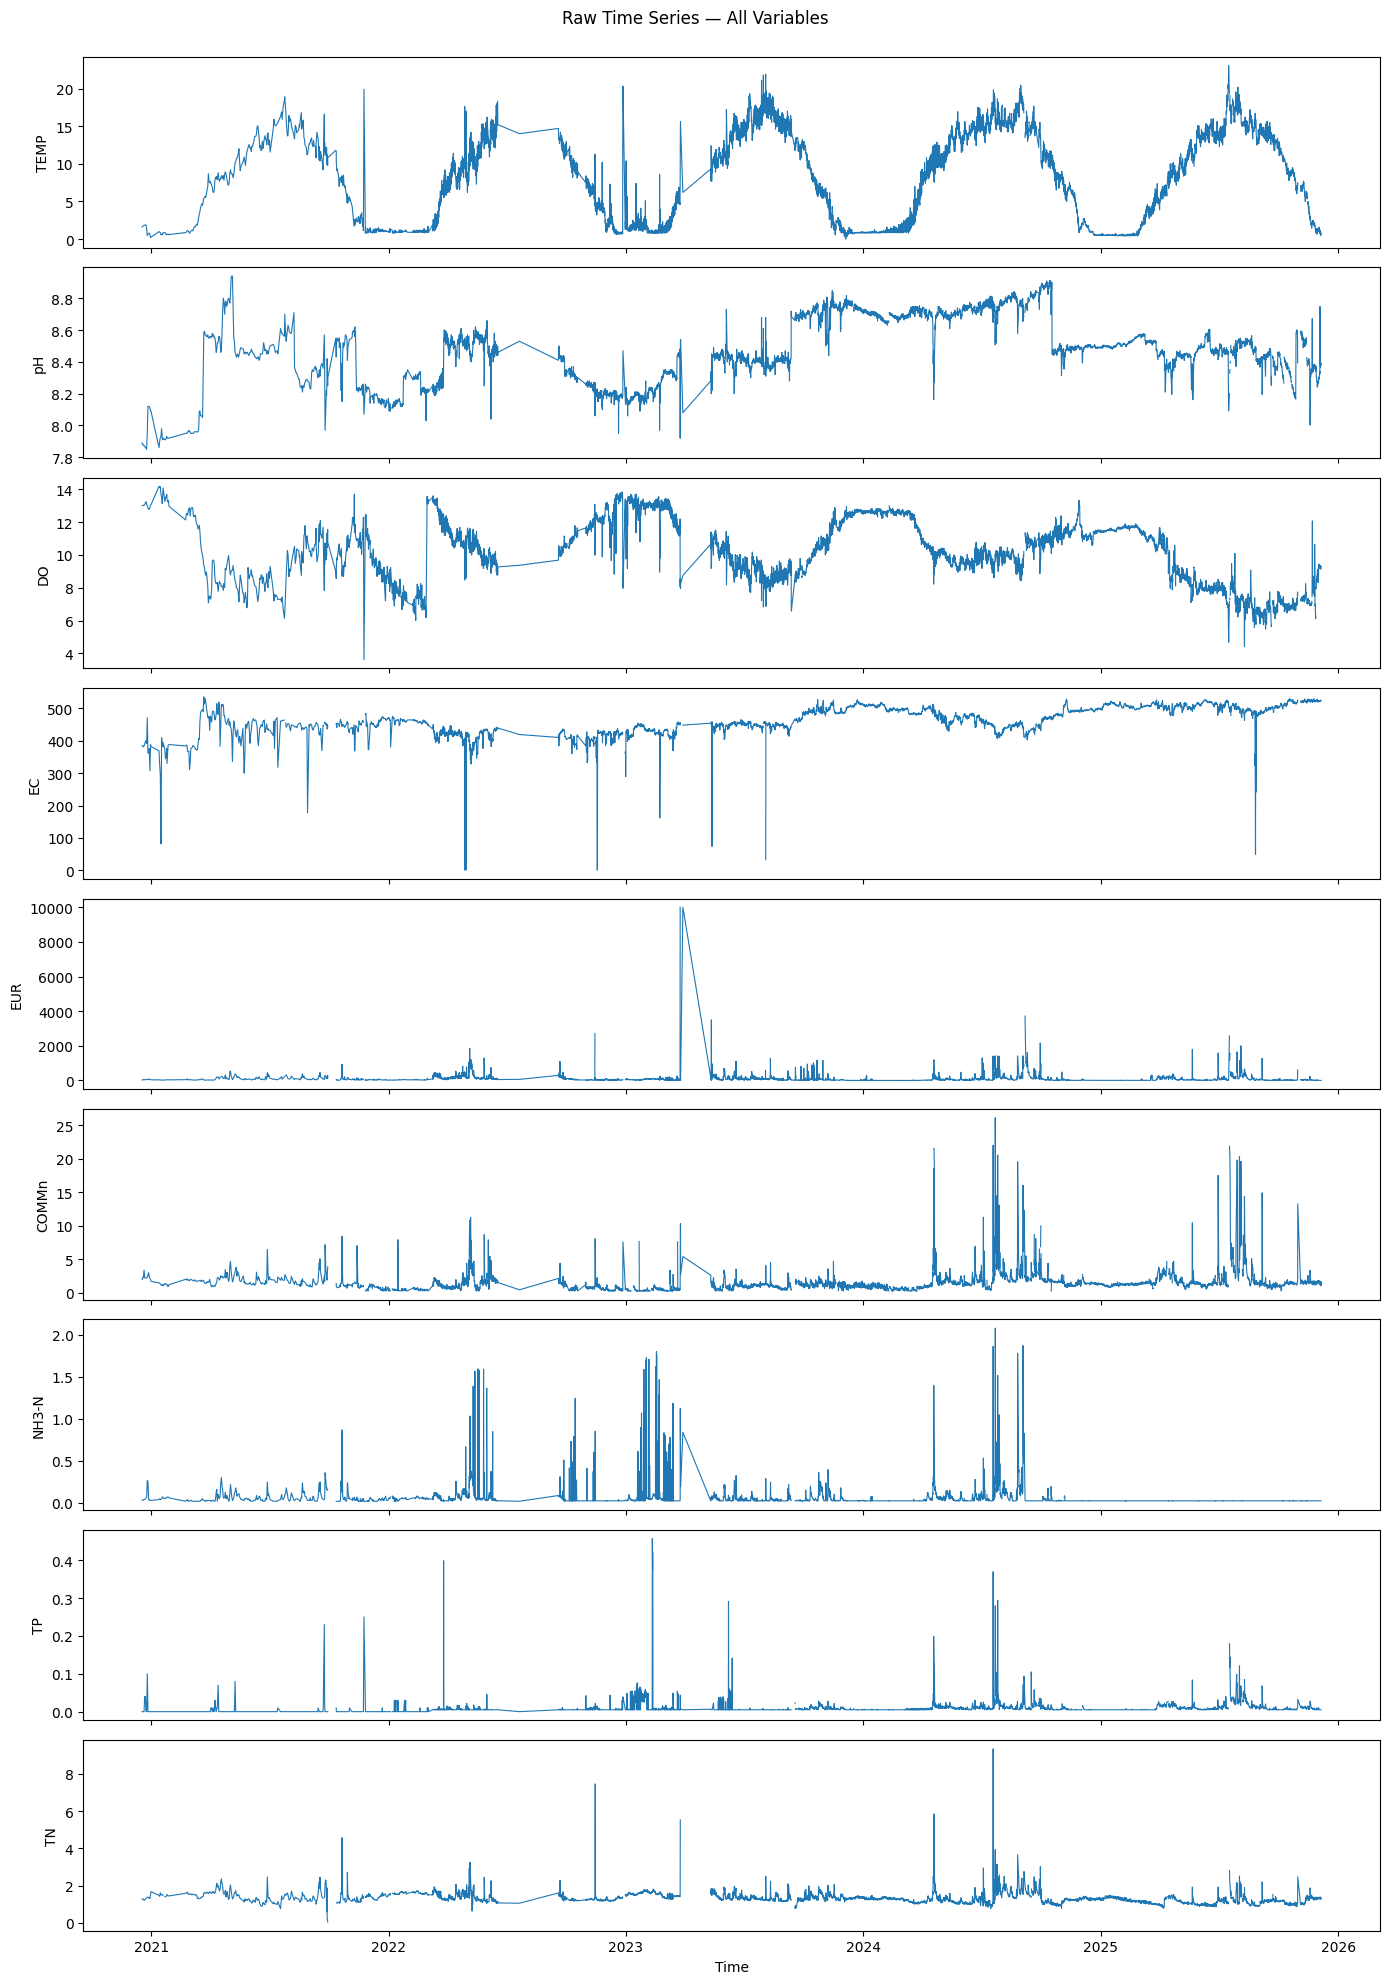

In [9]:
fig, axes = plt.subplots(len(FEATURE_COLS), 1, figsize=(14, 2.2 * len(FEATURE_COLS)), sharex=True)
for ax, col in zip(axes, FEATURE_COLS):
    ax.plot(raw_df["time"], raw_df[col], linewidth=0.8)
    ax.set_ylabel(col)
axes[-1].set_xlabel("Time")
fig.suptitle("Raw Time Series — All Variables", y=1.0)
plt.tight_layout()
plt.show()

In [10]:
# Regularize to a fixed 4-hour interval on a continuous time grid
df = raw_df.set_index("time")[FEATURE_COLS]

full_index = pd.date_range(start=df.index.min(), end=df.index.max(), freq="4H")
df = df.reindex(full_index)
df.index.name = "time"

# Handle missing values: linear interpolation, then fill any remaining
# edge NaNs (start/end of series) with forward/backward fill
df[FEATURE_COLS] = df[FEATURE_COLS].interpolate(method="linear", limit_direction="both")
df[FEATURE_COLS] = df[FEATURE_COLS].fillna(method="ffill").fillna(method="bfill")

print("Missing values after cleaning:")
print(df.isna().sum())
print("\nRegularized dataset shape:", df.shape)

df = df.reset_index()
df.head()

Missing values after cleaning:
TEMP     0
pH       0
DO       0
EC       0
EUR      0
COMMn    0
NH3-N    0
TP       0
TN       0
dtype: int64

Regularized dataset shape: (10884, 9)


,time,TEMP,pH,DO,EC,EUR,COMMn,NH3-N,TP,TN
0,2020-12-17 20:00:00,1.600000,7.890000,13.000000,385.25,23.250000,1.950000,0.03,0.0,1.280000
1,2020-12-18 00:00:00,1.616667,7.888333,13.001667,384.93,26.541667,2.001667,0.03,0.0,1.283333
2,2020-12-18 04:00:00,1.633333,7.886667,13.003333,384.61,29.833333,2.053333,0.03,0.0,1.286667
3,2020-12-18 08:00:00,1.650000,7.885000,13.005000,384.29,33.125000,2.105000,0.03,0.0,1.290000
4,2020-12-18 12:00:00,1.666667,7.883333,13.006667,383.97,36.416667,2.156667,0.03,0.0,1.293333


In [11]:
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)  # 70% + 15%

train_df = df.iloc[:train_end].reset_index(drop=True)
val_df = df.iloc[train_end:val_end].reset_index(drop=True)
test_df = df.iloc[val_end:].reset_index(drop=True)

print(f"Train: {len(train_df)} ({len(train_df)/n:.1%})")
print(f"Val:   {len(val_df)} ({len(val_df)/n:.1%})")
print(f"Test:  {len(test_df)} ({len(test_df)/n:.1%})")

Train: 7618 (70.0%)
Val:   1633 (15.0%)
Test:  1633 (15.0%)


In [12]:
scaler = StandardScaler()
scaler.fit(train_df[FEATURE_COLS].values)

train_scaled = scaler.transform(train_df[FEATURE_COLS].values)
val_scaled = scaler.transform(val_df[FEATURE_COLS].values)
test_scaled = scaler.transform(test_df[FEATURE_COLS].values)

print("Scaler fit on train set only.")
print("Train scaled shape:", train_scaled.shape)

Scaler fit on train set only.
Train scaled shape: (7618, 9)


In [13]:
def build_time_features(time_series):
    """time_series: pandas Series of datetimes -> (N, 4) array of normalized time features"""
    t = pd.DataFrame({"time": pd.to_datetime(time_series)})
    month = t["time"].dt.month.values / 12.0 - 0.5
    day = t["time"].dt.day.values / 31.0 - 0.5
    weekday = t["time"].dt.weekday.values / 6.0 - 0.5
    hour = t["time"].dt.hour.values / 23.0 - 0.5
    return np.stack([month, day, weekday, hour], axis=1).astype(np.float32)

train_time = build_time_features(train_df["time"])
val_time = build_time_features(val_df["time"])
test_time = build_time_features(test_df["time"])

TIME_FEAT_DIM = train_time.shape[1]
print("Time feature dim:", TIME_FEAT_DIM)

Time feature dim: 4


In [14]:
LOOKBACK = 24     # encoder input length
HORIZON = 6        # forecast horizon (prediction length)
LABEL_LEN = 12      # decoder start-token length (known history fed to decoder)

def create_windows(data_scaled, time_feats, target_idx, lookback, label_len, horizon):
    """
    Builds Informer-style samples:
      x_enc:      (lookback, n_features)
      x_mark_enc: (lookback, time_feat_dim)
      x_dec:      (label_len + horizon, n_features)  -- last label_len known steps + zeros for horizon
      x_mark_dec: (label_len + horizon, time_feat_dim)
      y:          (horizon,)  -- scaled DO values to predict
    """
    n_samples = len(data_scaled) - lookback - horizon + 1
    n_features = data_scaled.shape[1]

    X_enc, X_mark_enc, X_dec, X_mark_dec, Y = [], [], [], [], []

    for i in range(n_samples):
        s_enc = i
        e_enc = i + lookback
        s_dec_known = e_enc - label_len
        e_dec = e_enc + horizon

        enc_x = data_scaled[s_enc:e_enc]
        enc_mark = time_feats[s_enc:e_enc]

        dec_known = data_scaled[s_dec_known:e_enc]
        dec_future_placeholder = np.zeros((horizon, n_features), dtype=np.float32)
        dec_x = np.concatenate([dec_known, dec_future_placeholder], axis=0)
        dec_mark = time_feats[s_dec_known:e_dec]

        target = data_scaled[e_enc:e_dec, target_idx]

        X_enc.append(enc_x)
        X_mark_enc.append(enc_mark)
        X_dec.append(dec_x)
        X_mark_dec.append(dec_mark)
        Y.append(target)

    return (np.array(X_enc, dtype=np.float32),
            np.array(X_mark_enc, dtype=np.float32),
            np.array(X_dec, dtype=np.float32),
            np.array(X_mark_dec, dtype=np.float32),
            np.array(Y, dtype=np.float32))

Xe_tr, Xme_tr, Xd_tr, Xmd_tr, Y_tr = create_windows(train_scaled, train_time, TARGET_IDX, LOOKBACK, LABEL_LEN, HORIZON)
Xe_val, Xme_val, Xd_val, Xmd_val, Y_val = create_windows(val_scaled, val_time, TARGET_IDX, LOOKBACK, LABEL_LEN, HORIZON)
Xe_te, Xme_te, Xd_te, Xmd_te, Y_te = create_windows(test_scaled, test_time, TARGET_IDX, LOOKBACK, LABEL_LEN, HORIZON)

print("Encoder input shape (train):", Xe_tr.shape, " -> (batch, 24, 9)")
print("Decoder input shape (train):", Xd_tr.shape, f" -> (batch, {LABEL_LEN + HORIZON}, 9)")
print("Target shape (train):       ", Y_tr.shape, " -> (batch, 6)")

Encoder input shape (train): (7589, 24, 9)  -> (batch, 24, 9)
Decoder input shape (train): (7589, 18, 9)  -> (batch, 18, 9)
Target shape (train):        (7589, 6)  -> (batch, 6)


In [15]:
class DODataset(Dataset):
    def __init__(self, x_enc, x_mark_enc, x_dec, x_mark_dec, y):
        self.x_enc = torch.from_numpy(x_enc)
        self.x_mark_enc = torch.from_numpy(x_mark_enc)
        self.x_dec = torch.from_numpy(x_dec)
        self.x_mark_dec = torch.from_numpy(x_mark_dec)
        self.y = torch.from_numpy(y)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return (self.x_enc[idx], self.x_mark_enc[idx],
                self.x_dec[idx], self.x_mark_dec[idx], self.y[idx])


BATCH_SIZE = 32

train_ds = DODataset(Xe_tr, Xme_tr, Xd_tr, Xmd_tr, Y_tr)
val_ds = DODataset(Xe_val, Xme_val, Xd_val, Xmd_val, Y_val)
test_ds = DODataset(Xe_te, Xme_te, Xd_te, Xmd_te, Y_te)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)} | Test batches: {len(test_loader)}")

Train batches: 237 | Val batches: 51 | Test batches: 51


In [16]:
class PositionalEmbedding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model).float()
        pe.require_grad = False

        position = torch.arange(0, max_len).float().unsqueeze(1)
        div_term = (torch.arange(0, d_model, 2).float() * -(math.log(10000.0) / d_model)).exp()

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)
        self.register_buffer("pe", pe)

    def forward(self, x):
        return self.pe[:, :x.size(1)]


class TokenEmbedding(nn.Module):
    def __init__(self, c_in, d_model):
        super().__init__()
        self.tokenConv = nn.Conv1d(in_channels=c_in, out_channels=d_model,
                                    kernel_size=3, padding=1, padding_mode="circular", bias=False)
        for m in self.modules():
            if isinstance(m, nn.Conv1d):
                nn.init.kaiming_normal_(m.weight, mode="fan_in", nonlinearity="leaky_relu")

    def forward(self, x):
        # x: (B, L, C) -> (B, L, d_model)
        x = self.tokenConv(x.permute(0, 2, 1)).transpose(1, 2)
        return x


class TimeFeatureEmbedding(nn.Module):
    def __init__(self, d_model, time_feat_dim):
        super().__init__()
        self.embed = nn.Linear(time_feat_dim, d_model, bias=False)

    def forward(self, x_mark):
        return self.embed(x_mark)


class DataEmbedding(nn.Module):
    def __init__(self, c_in, d_model, time_feat_dim, dropout=0.1):
        super().__init__()
        self.value_embedding = TokenEmbedding(c_in=c_in, d_model=d_model)
        self.position_embedding = PositionalEmbedding(d_model=d_model)
        self.temporal_embedding = TimeFeatureEmbedding(d_model=d_model, time_feat_dim=time_feat_dim)
        self.dropout = nn.Dropout(p=dropout)

    def forward(self, x, x_mark):
        x = self.value_embedding(x) + self.position_embedding(x) + self.temporal_embedding(x_mark)
        return self.dropout(x)

print("Embedding modules defined.")

Embedding modules defined.


In [17]:
class ProbMask:
    def __init__(self, B, H, L, index, scores, device="cpu"):
        _mask = torch.ones(L, scores.shape[-1], dtype=torch.bool).to(device).triu(1)
        _mask_ex = _mask[None, None, :].expand(B, H, L, scores.shape[-1])
        indicator = _mask_ex[torch.arange(B)[:, None, None],
                              torch.arange(H)[None, :, None],
                              index, :].to(device)
        self._mask = indicator.view(scores.shape).to(device)

    @property
    def mask(self):
        return self._mask


class ProbAttention(nn.Module):
    def __init__(self, mask_flag=True, factor=5, scale=None, attention_dropout=0.1):
        super().__init__()
        self.factor = factor
        self.scale = scale
        self.mask_flag = mask_flag
        self.dropout = nn.Dropout(attention_dropout)

    def _prob_QK(self, Q, K, sample_k, n_top):
        # Q, K: (B, H, L, D)
        B, H, L_K, E = K.shape
        _, _, L_Q, _ = Q.shape

        K_expand = K.unsqueeze(-3).expand(B, H, L_Q, L_K, E)
        index_sample = torch.randint(L_K, (L_Q, sample_k), device=Q.device)
        K_sample = K_expand[:, :, torch.arange(L_Q, device=Q.device).unsqueeze(1), index_sample, :]
        Q_K_sample = torch.matmul(Q.unsqueeze(-2), K_sample.transpose(-2, -1)).squeeze(-2)

        # sparsity measurement M(qi, K)
        M = Q_K_sample.max(-1)[0] - torch.div(Q_K_sample.sum(-1), L_K)
        n_top = min(n_top, L_Q)
        M_top = M.topk(n_top, sorted=False)[1]

        Q_reduce = Q[torch.arange(B)[:, None, None],
                      torch.arange(H)[None, :, None],
                      M_top, :]
        Q_K = torch.matmul(Q_reduce, K.transpose(-2, -1))
        return Q_K, M_top

    def _get_initial_context(self, V, L_Q):
        B, H, L_V, D = V.shape
        if not self.mask_flag:
            V_sum = V.mean(dim=-2)
            context = V_sum.unsqueeze(-2).expand(B, H, L_Q, D).clone()
        else:
            assert L_Q == L_V, "mask_flag=True requires L_Q == L_V (self-attention)"
            context = V.cumsum(dim=-2)
        return context

    def _update_context(self, context_in, V, scores, index, L_Q):
        B, H, L_V, D = V.shape
        if self.mask_flag:
            attn_mask = ProbMask(B, H, L_Q, index, scores, device=V.device)
            scores = scores.masked_fill(attn_mask.mask, -np.inf) if False else scores.masked_fill(attn_mask.mask, float("-inf"))
        attn = torch.softmax(scores, dim=-1)
        update = torch.matmul(attn, V)
        context_in[torch.arange(B)[:, None, None],
                    torch.arange(H)[None, :, None],
                    index, :] = update.type_as(context_in)
        return context_in, attn

    def forward(self, queries, keys, values, attn_mask=None):
        # queries, keys, values: (B, L, H, D)
        B, L_Q, H, D = queries.shape
        _, L_K, _, _ = keys.shape

        queries = queries.transpose(2, 1)
        keys = keys.transpose(2, 1)
        values = values.transpose(2, 1)

        U_part = min(self.factor * int(np.ceil(np.log(L_K))), L_K)
        u = min(self.factor * int(np.ceil(np.log(L_Q))), L_Q)
        U_part = max(U_part, 1)
        u = max(u, 1)

        scores_top, index = self._prob_QK(queries, keys, sample_k=U_part, n_top=u)

        scale = self.scale or 1.0 / math.sqrt(D)
        scores_top = scores_top * scale

        context = self._get_initial_context(values, L_Q)
        context, attn = self._update_context(context, values, scores_top, index, L_Q)

        return context.transpose(2, 1).contiguous(), attn


class FullAttention(nn.Module):
    """Standard scaled dot-product attention, used for the decoder's cross-attention."""
    def __init__(self, mask_flag=False, scale=None, attention_dropout=0.1):
        super().__init__()
        self.mask_flag = mask_flag
        self.scale = scale
        self.dropout = nn.Dropout(attention_dropout)

    def forward(self, queries, keys, values, attn_mask=None):
        B, L, H, E = queries.shape
        _, S, _, D = values.shape
        scale = self.scale or 1.0 / math.sqrt(E)

        scores = torch.einsum("blhe,bshe->bhls", queries, keys)
        A = self.dropout(torch.softmax(scale * scores, dim=-1))
        V = torch.einsum("bhls,bshd->blhd", A, values)
        return V.contiguous(), A

print("ProbSparse and Full attention kernels defined.")

ProbSparse and Full attention kernels defined.


In [18]:
class AttentionLayer(nn.Module):
    def __init__(self, attention, d_model, n_heads, d_keys=None, d_values=None):
        super().__init__()
        d_keys = d_keys or (d_model // n_heads)
        d_values = d_values or (d_model // n_heads)

        self.inner_attention = attention
        self.query_projection = nn.Linear(d_model, d_keys * n_heads)
        self.key_projection = nn.Linear(d_model, d_keys * n_heads)
        self.value_projection = nn.Linear(d_model, d_values * n_heads)
        self.out_projection = nn.Linear(d_values * n_heads, d_model)
        self.n_heads = n_heads

    def forward(self, queries, keys, values, attn_mask=None):
        B, L, _ = queries.shape
        _, S, _ = keys.shape
        H = self.n_heads

        queries = self.query_projection(queries).view(B, L, H, -1)
        keys = self.key_projection(keys).view(B, S, H, -1)
        values = self.value_projection(values).view(B, S, H, -1)

        out, attn = self.inner_attention(queries, keys, values, attn_mask)
        out = out.view(B, L, -1)
        return self.out_projection(out), attn

print("AttentionLayer defined.")

AttentionLayer defined.


In [19]:
class EncoderLayer(nn.Module):
    def __init__(self, attention, d_model, d_ff=None, dropout=0.1, activation="gelu"):
        super().__init__()
        d_ff = d_ff or 4 * d_model
        self.attention = attention
        self.conv1 = nn.Conv1d(in_channels=d_model, out_channels=d_ff, kernel_size=1)
        self.conv2 = nn.Conv1d(in_channels=d_ff, out_channels=d_model, kernel_size=1)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        self.activation = F.gelu if activation == "gelu" else F.relu

    def forward(self, x, attn_mask=None):
        new_x, attn = self.attention(x, x, x, attn_mask)
        x = x + self.dropout(new_x)

        y = x = self.norm1(x)
        y = self.dropout(self.activation(self.conv1(y.transpose(-1, 1))))
        y = self.dropout(self.conv2(y).transpose(-1, 1))

        return self.norm2(x + y), attn

print("EncoderLayer defined.")

EncoderLayer defined.


In [20]:
class ConvLayer(nn.Module):
    def __init__(self, c_in):
        super().__init__()
        self.downConv = nn.Conv1d(in_channels=c_in, out_channels=c_in,
                                   kernel_size=3, padding=1, padding_mode="circular")
        self.norm = nn.BatchNorm1d(c_in)
        self.activation = nn.ELU()
        self.maxPool = nn.MaxPool1d(kernel_size=3, stride=2, padding=1)

    def forward(self, x):
        x = self.downConv(x.permute(0, 2, 1))
        x = self.norm(x)
        x = self.activation(x)
        x = self.maxPool(x)
        x = x.transpose(1, 2)
        return x

print("ConvLayer (distilling) defined.")

ConvLayer (distilling) defined.


In [21]:
class Encoder(nn.Module):
    def __init__(self, attn_layers, conv_layers=None, norm_layer=None):
        super().__init__()
        self.attn_layers = nn.ModuleList(attn_layers)
        self.conv_layers = nn.ModuleList(conv_layers) if conv_layers is not None else None
        self.norm = norm_layer

    def forward(self, x, attn_mask=None):
        attns = []
        if self.conv_layers is not None:
            for attn_layer, conv_layer in zip(self.attn_layers, self.conv_layers):
                x, attn = attn_layer(x, attn_mask=attn_mask)
                x = conv_layer(x)
                attns.append(attn)
            x, attn = self.attn_layers[-1](x, attn_mask=attn_mask)
            attns.append(attn)
        else:
            for attn_layer in self.attn_layers:
                x, attn = attn_layer(x, attn_mask=attn_mask)
                attns.append(attn)

        if self.norm is not None:
            x = self.norm(x)
        return x, attns

print("Encoder defined.")

Encoder defined.


In [22]:
class DecoderLayer(nn.Module):
    def __init__(self, self_attention, cross_attention, d_model, d_ff=None, dropout=0.1, activation="gelu"):
        super().__init__()
        d_ff = d_ff or 4 * d_model
        self.self_attention = self_attention
        self.cross_attention = cross_attention
        self.conv1 = nn.Conv1d(in_channels=d_model, out_channels=d_ff, kernel_size=1)
        self.conv2 = nn.Conv1d(in_channels=d_ff, out_channels=d_model, kernel_size=1)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        self.activation = F.gelu if activation == "gelu" else F.relu

    def forward(self, x, cross, x_mask=None, cross_mask=None):
        x = x + self.dropout(self.self_attention(x, x, x, x_mask)[0])
        x = self.norm1(x)

        x = x + self.dropout(self.cross_attention(x, cross, cross, cross_mask)[0])
        y = x = self.norm2(x)

        y = self.dropout(self.activation(self.conv1(y.transpose(-1, 1))))
        y = self.dropout(self.conv2(y).transpose(-1, 1))

        return self.norm3(x + y)

print("DecoderLayer defined.")

DecoderLayer defined.


In [23]:
class Decoder(nn.Module):
    def __init__(self, layers, norm_layer=None):
        super().__init__()
        self.layers = nn.ModuleList(layers)
        self.norm = norm_layer

    def forward(self, x, cross, x_mask=None, cross_mask=None):
        for layer in self.layers:
            x = layer(x, cross, x_mask=x_mask, cross_mask=cross_mask)
        if self.norm is not None:
            x = self.norm(x)
        return x

print("Decoder defined.")

Decoder defined.


In [24]:
class Informer(nn.Module):
    def __init__(self, enc_in, dec_in, c_out, seq_len, label_len, out_len,
                 factor=5, d_model=128, n_heads=8, e_layers=2, d_layers=1, d_ff=256,
                 dropout=0.2, time_feat_dim=4, activation="gelu", distil=True):
        super().__init__()
        self.pred_len = out_len
        self.label_len = label_len

        self.enc_embedding = DataEmbedding(enc_in, d_model, time_feat_dim, dropout)
        self.dec_embedding = DataEmbedding(dec_in, d_model, time_feat_dim, dropout)

        self.encoder = Encoder(
            [EncoderLayer(
                AttentionLayer(ProbAttention(mask_flag=False, factor=factor, attention_dropout=dropout),
                               d_model, n_heads),
                d_model, d_ff, dropout, activation)
             for _ in range(e_layers)],
            [ConvLayer(d_model) for _ in range(e_layers - 1)] if distil else None,
            norm_layer=nn.LayerNorm(d_model)
        )

        self.decoder = Decoder(
            [DecoderLayer(
                AttentionLayer(ProbAttention(mask_flag=True, factor=factor, attention_dropout=dropout),
                               d_model, n_heads),
                AttentionLayer(FullAttention(mask_flag=False, attention_dropout=dropout),
                               d_model, n_heads),
                d_model, d_ff, dropout, activation)
             for _ in range(d_layers)],
            norm_layer=nn.LayerNorm(d_model)
        )

        self.projection = nn.Linear(d_model, c_out, bias=True)

    def forward(self, x_enc, x_mark_enc, x_dec, x_mark_dec):
        enc_out = self.enc_embedding(x_enc, x_mark_enc)
        enc_out, attns = self.encoder(enc_out, attn_mask=None)

        dec_out = self.dec_embedding(x_dec, x_mark_dec)
        dec_out = self.decoder(dec_out, enc_out, x_mask=None, cross_mask=None)
        dec_out = self.projection(dec_out)

        return dec_out[:, -self.pred_len:, :]  # (B, pred_len, c_out)


N_FEATURES = len(FEATURE_COLS)

model = Informer(
    enc_in=N_FEATURES,
    dec_in=N_FEATURES,
    c_out=1,
    seq_len=LOOKBACK,
    label_len=LABEL_LEN,
    out_len=HORIZON,
    factor=5,
    d_model=128,
    n_heads=8,
    e_layers=2,
    d_layers=1,
    d_ff=256,
    dropout=0.2,
    time_feat_dim=TIME_FEAT_DIM,
    activation="gelu",
    distil=True
).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Informer model created. Trainable parameters: {n_params:,}")

Informer model created. Trainable parameters: 521,857


In [25]:
criterion = nn.MSELoss()
print("Loss function: MSELoss")

Loss function: MSELoss


In [26]:
LEARNING_RATE = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print(f"Optimizer: Adam (lr={LEARNING_RATE})")

Optimizer: Adam (lr=0.001)


In [27]:
scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3, min_lr=1e-6)
print("Scheduler: ReduceLROnPlateau")

Scheduler: ReduceLROnPlateau


In [28]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.0, path="best_informer_do.pt"):
        self.patience = patience
        self.min_delta = min_delta
        self.path = path
        self.best_loss = np.inf
        self.counter = 0
        self.early_stop = False

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            torch.save(model.state_dict(), self.path)
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        return self.early_stop

early_stopping = EarlyStopping(patience=10, path="best_informer_do.pt")
print("Early stopping configured with patience=10")

Early stopping configured with patience=10


In [29]:
EPOCHS = 100
CLIP_GRAD = 5.0

def run_epoch(loader, train_mode=True):
    model.train() if train_mode else model.eval()
    total_loss = 0.0

    context = torch.enable_grad() if train_mode else torch.no_grad()
    with context:
        for x_enc, x_mark_enc, x_dec, x_mark_dec, y in loader:
            x_enc = x_enc.to(DEVICE)
            x_mark_enc = x_mark_enc.to(DEVICE)
            x_dec = x_dec.to(DEVICE)
            x_mark_dec = x_mark_dec.to(DEVICE)
            y = y.to(DEVICE)

            if train_mode:
                optimizer.zero_grad()

            out = model(x_enc, x_mark_enc, x_dec, x_mark_dec)  # (B, horizon, 1)
            out = out.squeeze(-1)  # (B, horizon)

            loss = criterion(out, y)

            if train_mode:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_GRAD)
                optimizer.step()

            total_loss += loss.item() * x_enc.size(0)

    return total_loss / len(loader.dataset)


train_losses, val_losses = [], []
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    train_loss = run_epoch(train_loader, train_mode=True)
    val_loss = run_epoch(val_loader, train_mode=False)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]["lr"]

    stop = early_stopping(val_loss, model)

    print(f"Epoch {epoch:3d}/{EPOCHS} | train_loss={train_loss:.5f} | val_loss={val_loss:.5f} "
          f"| lr={current_lr:.2e} | time={time.time()-t0:.1f}s")

    if stop:
        print(f"Early stopping triggered at epoch {epoch}.")
        break

total_time = time.time() - start_time
print(f"\nTotal training time: {total_time:.1f}s")

Epoch   1/100 | train_loss=0.11790 | val_loss=0.04599 | lr=1.00e-03 | time=8.6s
Epoch   2/100 | train_loss=0.07246 | val_loss=0.05342 | lr=1.00e-03 | time=7.0s
Epoch   3/100 | train_loss=0.06503 | val_loss=0.05835 | lr=1.00e-03 | time=6.1s
Epoch   4/100 | train_loss=0.06012 | val_loss=0.07992 | lr=1.00e-03 | time=7.0s
Epoch   5/100 | train_loss=0.05802 | val_loss=0.08862 | lr=5.00e-04 | time=5.8s
Epoch   6/100 | train_loss=0.04955 | val_loss=0.07749 | lr=5.00e-04 | time=6.4s
Epoch   7/100 | train_loss=0.04678 | val_loss=0.08527 | lr=5.00e-04 | time=5.9s
Epoch   8/100 | train_loss=0.04481 | val_loss=0.09624 | lr=5.00e-04 | time=6.5s
Epoch   9/100 | train_loss=0.04461 | val_loss=0.10266 | lr=2.50e-04 | time=5.9s
Epoch  10/100 | train_loss=0.03956 | val_loss=0.12101 | lr=2.50e-04 | time=6.3s
Epoch  11/100 | train_loss=0.03781 | val_loss=0.10783 | lr=2.50e-04 | time=6.0s
Early stopping triggered at epoch 11.

Total training time: 71.4s


In [30]:
# The EarlyStopping callback already checkpoints the best model to disk on every improvement.
print(f"Best validation loss: {early_stopping.best_loss:.5f}")
print(f"Best model checkpoint saved to: {early_stopping.path}")

model.load_state_dict(torch.load(early_stopping.path, map_location=DEVICE))
print("Best model weights loaded into `model`.")

Best validation loss: 0.04599
Best model checkpoint saved to: best_informer_do.pt
Best model weights loaded into `model`.


In [31]:
def inverse_transform_target(scaled_values, scaler, target_idx, n_features):
    """scaled_values: (..., ) array of scaled DO values -> inverse-transformed to original units"""
    shape = scaled_values.shape
    flat = scaled_values.reshape(-1)
    dummy = np.zeros((flat.shape[0], n_features), dtype=np.float32)
    dummy[:, target_idx] = flat
    inv = scaler.inverse_transform(dummy)[:, target_idx]
    return inv.reshape(shape)


model.eval()
all_preds, all_trues = [], []

with torch.no_grad():
    for x_enc, x_mark_enc, x_dec, x_mark_dec, y in test_loader:
        x_enc = x_enc.to(DEVICE)
        x_mark_enc = x_mark_enc.to(DEVICE)
        x_dec = x_dec.to(DEVICE)
        x_mark_dec = x_mark_dec.to(DEVICE)

        out = model(x_enc, x_mark_enc, x_dec, x_mark_dec).squeeze(-1).cpu().numpy()
        all_preds.append(out)
        all_trues.append(y.numpy())

preds_scaled = np.concatenate(all_preds, axis=0)   # (N, horizon)
trues_scaled = np.concatenate(all_trues, axis=0)   # (N, horizon)

preds = inverse_transform_target(preds_scaled, scaler, TARGET_IDX, N_FEATURES)
trues = inverse_transform_target(trues_scaled, scaler, TARGET_IDX, N_FEATURES)

print("Predictions shape:", preds.shape)
print("Ground truth shape:", trues.shape)

Predictions shape: (1604, 6)
Ground truth shape: (1604, 6)


In [32]:
def mape(y_true, y_pred, eps=1e-6):
    return np.mean(np.abs((y_true - y_pred) / np.clip(np.abs(y_true), eps, None))) * 100

per_step_metrics = []
for step in range(HORIZON):
    yt, yp = trues[:, step], preds[:, step]
    rmse = math.sqrt(mean_squared_error(yt, yp))
    mae = mean_absolute_error(yt, yp)
    mp = mape(yt, yp)
    r2 = r2_score(yt, yp)
    per_step_metrics.append({"step": step + 1, "RMSE": rmse, "MAE": mae, "MAPE": mp, "R2": r2})

metrics_df = pd.DataFrame(per_step_metrics)
print("Per-step metrics:")
display(metrics_df)

overall_rmse = math.sqrt(mean_squared_error(trues.flatten(), preds.flatten()))
overall_mae = mean_absolute_error(trues.flatten(), preds.flatten())
overall_mape = mape(trues.flatten(), preds.flatten())
overall_r2 = r2_score(trues.flatten(), preds.flatten())

print("\nOverall metrics:")
print(f"RMSE: {overall_rmse:.4f}")
print(f"MAE:  {overall_mae:.4f}")
print(f"MAPE: {overall_mape:.2f}%")
print(f"R2:   {overall_r2:.4f}")

Per-step metrics:


,step,RMSE,MAE,MAPE,R2
0,1,0.585921,0.452841,5.889858,0.814636
1,2,0.585173,0.454874,5.863428,0.814659
2,3,0.607310,0.470360,6.025627,0.799911
3,4,0.623671,0.483573,6.189858,0.788499
4,5,0.616999,0.480476,6.158833,0.792556
5,6,0.652512,0.509765,6.519530,0.767460



Overall metrics:
RMSE: 0.6124
MAE:  0.4753
MAPE: 6.11%
R2:   0.7963
